<a href="https://colab.research.google.com/github/prajwalms07/DAV_Lab_Programs/blob/main/4NI25CS141prg_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
df = pd.read_csv(r"/content/StudentsPerformance.csv")

In [17]:
#Display First 5 Rows
print("First 5 rows of Dataset")
print(df.head())

print("\n")

First 5 rows of Dataset
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

 


In [19]:
print("\nDataset shape:")
print(df.shape)

data = df["math score"].dropna()

print("\nNumber of math score values:", len(data))

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)

IQR = q3 - q1

lowerlimit = q1 - 1.5 * IQR
upperlimit = q3 + 1.5 * IQR

print("\nIQR method")
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", IQR)

print("Lower limit:", lowerlimit)
print("Upper limit:", upperlimit)

iqr_outliers = df[
    (df["math score"] < lowerlimit) |
    (df["math score"] > upperlimit)
]

print("Number of IQR outliers:", len(iqr_outliers))

mean = data.mean()
std = data.std()

df["z score"] = (df["math score"] - mean) / std

# Corrected the typo here:
z_outliers = df[df["z score"].abs() > 3]
print("Number of Z-score outliers:", len(z_outliers))
display(z_outliers)


Dataset shape:
(1000, 9)

Number of math score values: 1000

IQR method
Q1: 57.0
Q3: 77.0
IQR: 20.0
Lower limit: 27.0
Upper limit: 107.0
Number of IQR outliers: 8
Number of Z-score outliers: 4


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,z score
17,female,group B,some high school,free/reduced,none,18,32,28,-3.171453
59,female,group C,some high school,free/reduced,none,0,17,10,-4.358547
787,female,group B,some college,standard,none,19,38,32,-3.105504
980,female,group B,high school,free/reduced,none,8,24,23,-3.830950


In [22]:
#5 OUTLIER DETECTION USING Z-SCORE METHOD

#calculate mean
mean = data.mean()

#calculate sd
std = data.std()

#Calculate Z-score for each math score
df["z score"] = (df["math score" ] - mean) / std

#find values
z_outliers = df[df["z score"].abs() > 3]

print("\nZ-SCORE METHOD")
print("Mean:", mean)
print("Standard deviation:", std)
print("Number of Z-score outliers:", len(z_outliers))


Z-SCORE METHOD
Mean: 66.089
Standard deviation: 15.163080096009468
Number of Z-score outliers: 4


In [27]:
#Display IQR Outliers
print("\nIQR OUTLIERS")

if len(iqr_outliers) > 0:
  print("Number of IQR outliers:", len(iqr_outliers))
  display(iqr_outliers)
else:
  print("No IQR outliers found")

print("\nZ-SCORE OUTLIERS")
if len(z_outliers) > 0:
  # Corrected column name to "z score" with a space
  print(z_outliers[["math score", "z score"]])
else:
  print("No Z-score outliers found.")

df["math_score_treated"] = df["math score"].clip(
    lower=lowerlimit,
    upper=upperlimit
)
print("Treatment Method: Capping using IQR limits")


IQR OUTLIERS
Number of IQR outliers: 8


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,z score
17,female,group B,some high school,free/reduced,none,18,32,28,-3.171453
59,female,group C,some high school,free/reduced,none,0,17,10,-4.358547
145,female,group C,some college,free/reduced,none,22,39,33,-2.907655
338,female,group B,some high school,free/reduced,none,24,38,27,-2.775755
466,female,group D,associate's degree,free/reduced,none,26,31,38,-2.643856
787,female,group B,some college,standard,none,19,38,32,-3.105504
842,female,group B,high school,free/reduced,completed,23,44,36,-2.841705
980,female,group B,high school,free/reduced,none,8,24,23,-3.830950



Z-SCORE OUTLIERS
     math score   z score
17           18 -3.171453
59            0 -4.358547
787          19 -3.105504
980           8 -3.830950
Treatment Method: Capping using IQR limits


In [28]:
#compare before and after treatment
print("\nBefore Treatment")
print(df["math score"].describe())
print("\nAfter Treatment")
print(df["math_score_treated"].describe())



Before Treatment
count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64

After Treatment
count    1000.000000
mean       66.165000
std        14.922414
min        27.000000
25%        57.000000
50%        66.000000
75%        77.000000
max       100.000000
Name: math_score_treated, dtype: float64


In [29]:
#Display Original And Treated Values

comparison = df[["math score","math_score_treated"]]
print(comparison.head(20))

    math score  math_score_treated
0           72                  72
1           69                  69
2           90                  90
3           47                  47
4           76                  76
5           71                  71
6           88                  88
7           40                  40
8           64                  64
9           38                  38
10          58                  58
11          40                  40
12          65                  65
13          78                  78
14          50                  50
15          69                  69
16          88                  88
17          18                  27
18          46                  46
19          54                  54


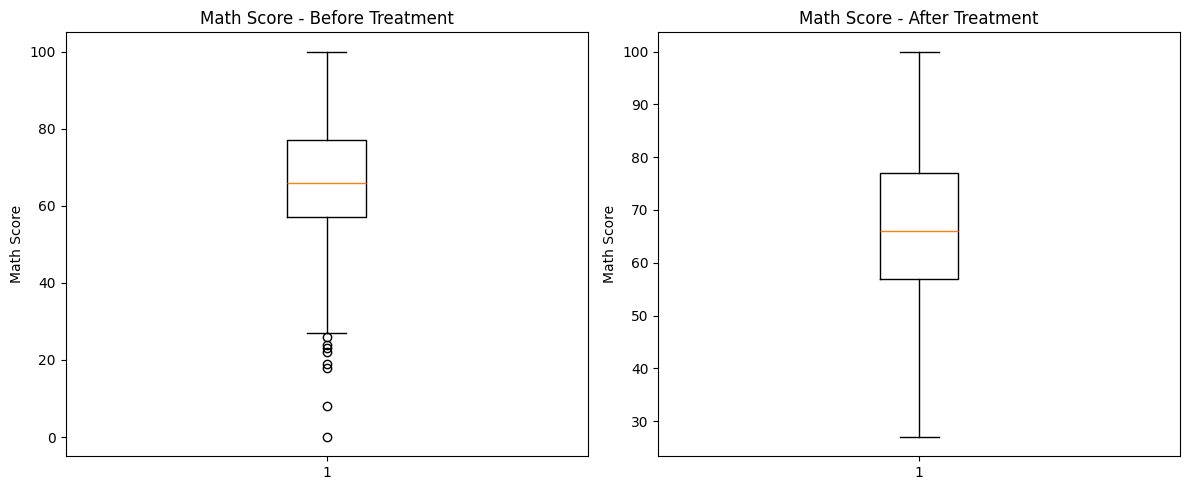

In [30]:
#10. Visualisation

plt.figure(figsize=(12, 5))

#---------BEFORE TREATMENT-------------
plt.subplot(1, 2, 1)
plt.boxplot(df["math score"].dropna())
plt.title("Math Score - Before Treatment")
plt.ylabel("Math Score")

#---------AFTER TREATMENT-------------
plt.subplot(1, 2, 2)
plt.boxplot(df["math_score_treated"].dropna())
plt.title("Math Score - After Treatment")
plt.ylabel("Math Score")

# Adjust spacing
plt.tight_layout()

# Display the plots
plt.show()